# 전처리

## 최소 전처리
| 항목               | 설명                          |
| ---------------- | --------------------------- |
| `Gender_encoded` | 성별: male → 1, female → 0    |
| `Height_m`       | 키(cm → m 단위) 변환             |
| `BMI`            | 체질량지수: Weight / Height(m)^2 |


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# 데이터 업로드
from google.colab import files
uploaded = files.upload()

# 파일 경로
file_path = "calories.csv"
df_calories = pd.read_csv("calories.csv")

# 최소 전처리 함수 정의
def preprocess_minimal(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [col.strip() for col in df.columns]

    # 성별 인코딩
    if 'Gender' in df.columns:
        le = LabelEncoder()
        df['Gender_encoded'] = le.fit_transform(df['Gender'])

    # BMI 계산 (키가 cm 단위일 경우 -> m 단위로 변환 후 계산)
    if 'Height' in df.columns and 'Weight' in df.columns:
        df['Height_m'] = df['Height'] / 100
        df['BMI'] = df['Weight'] / (df['Height_m'] ** 2)

    return df

# 전처리 수행
df_minimal = preprocess_minimal(df_calories)

# 결과 미리보기
df_minimal.head()

Saving calories.csv to calories.csv


,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories,Gender_encoded,Height_m,BMI
0,14733363,male,68,190,94,29,105,40.8,231,1,1.90,26.038781
1,14861698,female,20,166,60,14,94,40.3,66,0,1.66,21.773842
2,11179863,male,69,179,79,5,88,38.7,26,1,1.79,24.655910
3,16180408,female,34,179,71,13,100,40.5,71,0,1.79,22.159109
4,17771927,female,27,154,58,10,81,39.8,35,0,1.54,24.456063


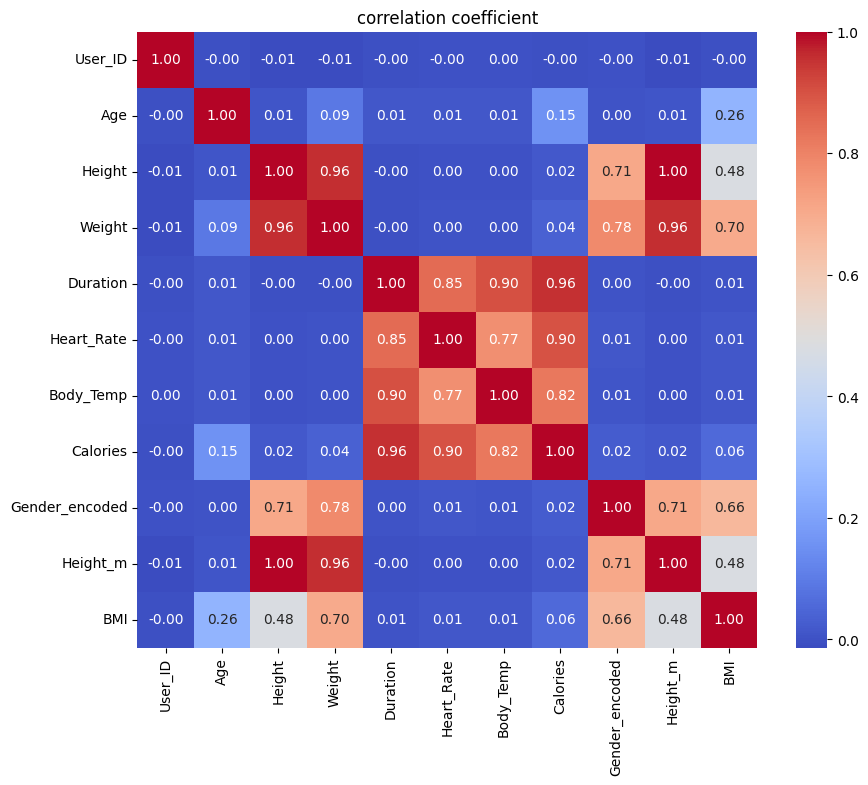

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 상관계수 행렬 구하기
corr = df_minimal.corr(numeric_only=True)

# 히트맵으로 시각화
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("correlation coefficient")
plt.show()

## 고급 전처리

| 변수명                      | 설명                             |
| ------------------------ | ------------------------------ |
| `Gender_encoded`         | 성별 (male=1, female=0)          |
| `Height_m`, `BMI`        | 키 단위 변환 및 체질량지수                |
| `Duration_per_kg`        | 체중 대비 운동 시간                    |
| `HeartRate_per_BMI`      | BMI당 심박수                       |
| `Is_Senior`              | 60세 이상 여부                      |
| `Age_bin_*`              | 나이 구간별 원-핫 인코딩 (예: 30대, 40대 등) |
| `BPM_to_Duration`        | 심박수 대비 운동 시간                   |
| `Gender_BMI_Interaction` | 성별과 BMI 간 상호작용 변수              |


In [ ]:
# 고급 전처리 함수 (preprocess_full) 정의
def preprocess_full(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [col.strip() for col in df.columns]

    # 성별 인코딩
    if 'Gender' in df.columns:
        le = LabelEncoder()
        df['Gender_encoded'] = le.fit_transform(df['Gender'])

    # 키 변환 (cm → m), BMI 계산
    if 'Height' in df.columns:
        df['Height_m'] = df['Height'] / 100
    if 'Weight' in df.columns and 'Height_m' in df.columns:
        df['BMI'] = df['Weight'] / (df['Height_m'] ** 2)

    # 파생 변수 생성
    if {'Duration', 'Weight'}.issubset(df.columns):
        df['Duration_per_kg'] = df['Duration'] / df['Weight']
    if {'Heart_Rate', 'BMI'}.issubset(df.columns):
        df['HeartRate_per_BMI'] = df['Heart_Rate'] / df['BMI']
    if 'Age' in df.columns:
        df['Is_Senior'] = (df['Age'] >= 60).astype(int)
        df['Age_bin'] = pd.cut(df['Age'], bins=[0, 29, 39, 49, 59, 100], labels=['20s', '30s', '40s', '50s', '60s+'])
    if {'Heart_Rate', 'Duration'}.issubset(df.columns):
        df['BPM_to_Duration'] = df['Heart_Rate'] / (df['Duration'] + 0.01)
    if {'Gender_encoded', 'BMI'}.issubset(df.columns):
        df['Gender_BMI_Interaction'] = df['Gender_encoded'] * df['BMI']

    # 원-핫 인코딩 (Age_bin)
    df = pd.get_dummies(df, columns=['Age_bin'], drop_first=True)

    return df

# 고급 전처리 적용
df_full = preprocess_full(df_calories)

# 결과 미리보기
from IPython.display import display
display(df_full.head())


,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories,Gender_encoded,...,BMI,Duration_per_kg,HeartRate_per_BMI,Is_Senior,BPM_to_Duration,Gender_BMI_Interaction,Age_bin_30s,Age_bin_40s,Age_bin_50s,Age_bin_60s+
0,14733363,male,68,190,94,29,105,40.8,231,1,...,26.038781,0.308511,4.032447,1,3.619442,26.038781,False,False,False,True
1,14861698,female,20,166,60,14,94,40.3,66,0,...,21.773842,0.233333,4.317107,0,6.709493,0.000000,False,False,False,False
2,11179863,male,69,179,79,5,88,38.7,26,1,...,24.655910,0.063291,3.569124,1,17.564870,24.655910,False,False,False,True
3,16180408,female,34,179,71,13,100,40.5,71,0,...,22.159109,0.183099,4.512817,0,7.686395,0.000000,True,False,False,False
4,17771927,female,27,154,58,10,81,39.8,35,0,...,24.456063,0.172414,3.312062,0,8.091908,0.000000,False,False,False,False


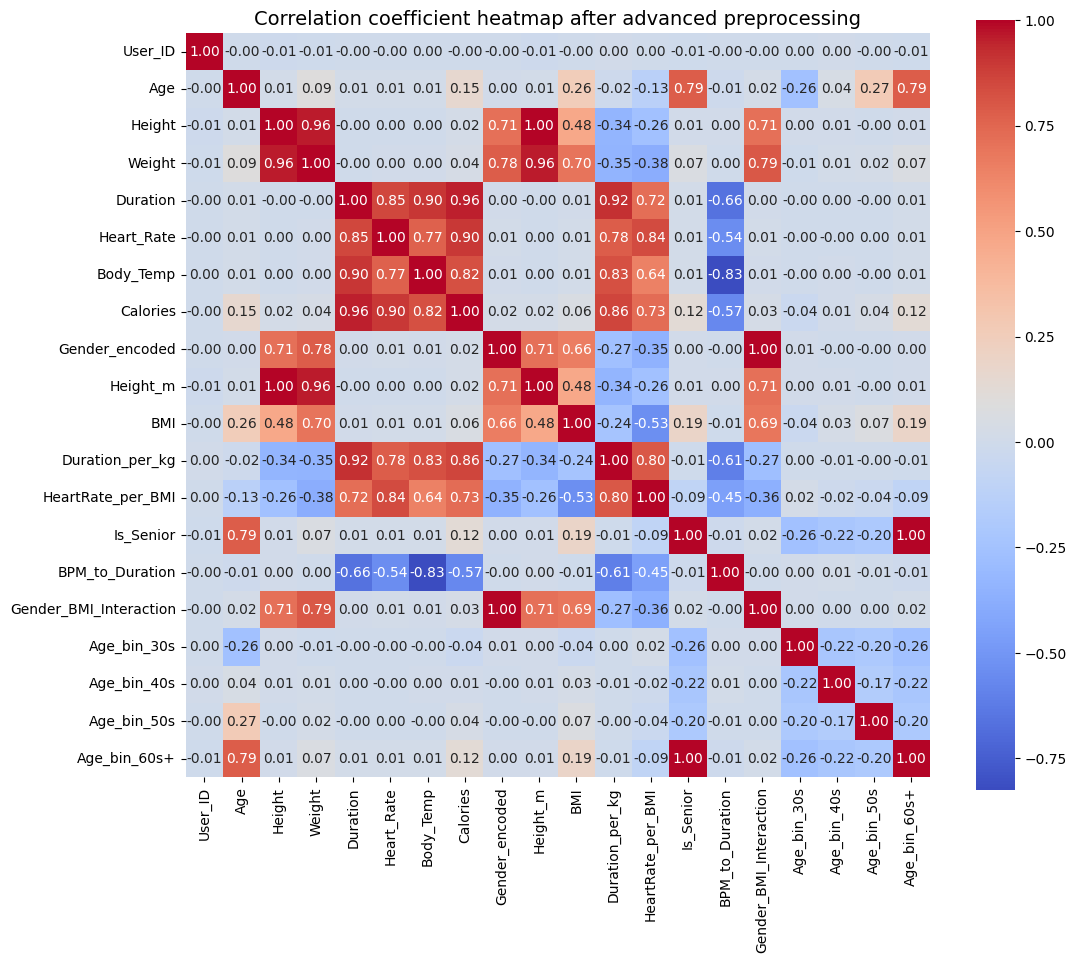

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 숫자형 변수만 추출하여 상관계수 계산
corr_full = df_full.corr(numeric_only=True)

# 히트맵 시각화
plt.figure(figsize=(12, 10))
sns.heatmap(corr_full, annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title("Correlation coefficient heatmap after advanced preprocessing", fontsize=14)
plt.show()

### 상관관계 해석 (calories와의)
| 변수                                     | 상관계수 (대략)        | 해석                    |
| -------------------------------------- | ---------------- | --------------------- |
| `Duration`                             | **+0.96**        | 매우 강한 양의 상관 (→ 포함)    |
| `Body_Temp`                            | +0.82            | 강한 양의 상관 (→ 포함)       |
| `Heart_Rate`                           | +0.77            | 양의 상관 (→ 포함)          |
| `Duration_per_kg`, `HeartRate_per_BMI` | +0.83, +0.64     | 유용한 파생변수 (→ 포함)       |
| `BPM_to_Duration`                      | **-0.57**        | 음의 상관도 유의미함 (→ 포함 가능) |
| `Gender_encoded`, `BMI`, `Is_Senior`   | 약한 상관 (0.1\~0.2) | 성능이 별로면 제거 고려         |


###  Recursive Feature Elimination (RFE)

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.feature_selection import RFE
from sklearn.model_selection import train_test_split

# 타겟과 입력 변수 분리
X = df_full.drop(columns=['User_ID', 'Calories', 'Height'])  # 중복 높은 Height는 제거
y = df_full['Calories']

# 범주형 변수 처리 (원-핫 인코딩 된 Age_bin은 이미 수치형)
X = X.select_dtypes(include=['float64', 'int64'])

# 학습용/검증용 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# RFE 적용 (Ridge 모델 기준, 상위 10개 변수 선택)
estimator = Ridge()
selector = RFE(estimator, n_features_to_select=10)
selector = selector.fit(X_train, y_train)

# 선택된 변수 이름 추출
selected_features = X_train.columns[selector.support_]
selected_features_df = X_train[selected_features].copy()

from IPython.display import display
display(selected_features_df.head())

# 10가지 변수 선택됨 (Weight	Duration	Heart_Rate	Body_Temp	Gender_encoded	Height_m	BMI	Duration_per_kg	HeartRate_per_BMI	Gender_BMI_Interaction)

,Weight,Duration,Heart_Rate,Body_Temp,Gender_encoded,Height_m,BMI,Duration_per_kg,HeartRate_per_BMI,Gender_BMI_Interaction
9839,77,7,81,39.5,1,1.79,24.031709,0.090909,3.370547,24.031709
9680,87,26,110,40.5,1,1.95,22.879684,0.298851,4.807759,22.879684
7093,77,12,88,40.1,1,1.81,23.503556,0.155844,3.744114,23.503556
11293,54,9,77,39.5,0,1.56,22.189349,0.166667,3.470133,0.000000
820,49,5,90,39.0,0,1.44,23.630401,0.102041,3.808653,0.000000


XGBoost 성능 (RFE 변수 기반)
RMSE: 10.73
R² Score: 0.9715


<ipython-input-8-431289101035>:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')


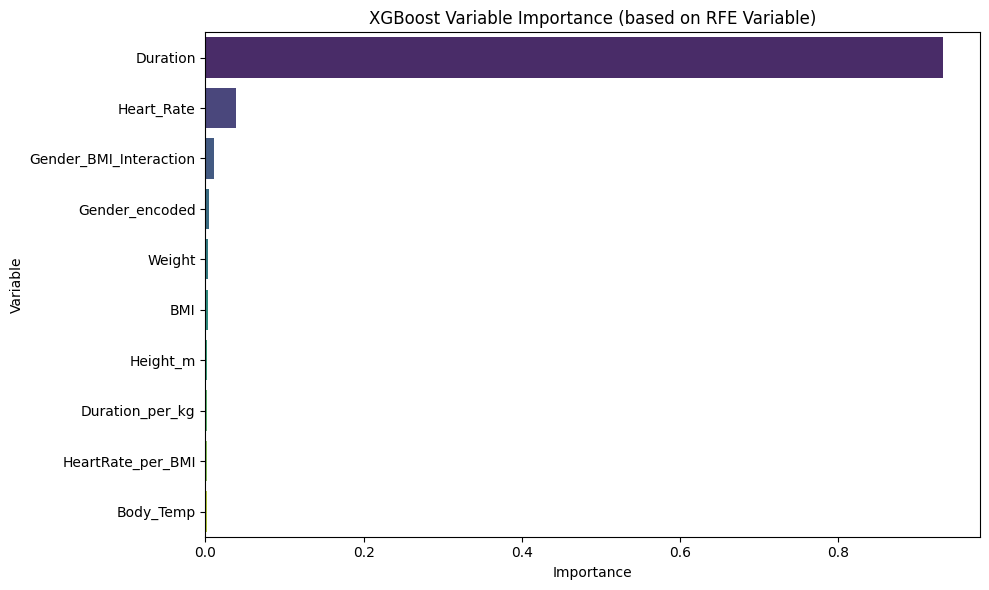

,Feature,Importance
1,Duration,0.932284
2,Heart_Rate,0.038497
9,Gender_BMI_Interaction,0.011016
4,Gender_encoded,0.004011
0,Weight,0.003611
6,BMI,0.003215
5,Height_m,0.002203
7,Duration_per_kg,0.002046
8,HeartRate_per_BMI,0.001658
3,Body_Temp,0.001458


In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.metrics import mean_squared_error
import numpy as np

# RFE로 선택된 변수만 사용
X_selected = X_train[selected_features]
X_selected_test = X_test[selected_features]

# XGBoost 모델 학습
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_model.fit(X_selected, y_train)

# 예측 및 성능 평가
y_pred = xgb_model.predict(X_selected_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred)) # RMSE 수동 계산
r2 = r2_score(y_test, y_pred)

# 성능 출력
print(f"XGBoost 성능 (RFE 변수 기반)")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

# 변수 중요도 시각화
importances = xgb_model.feature_importances_
importance_df = pd.DataFrame({'Feature': selected_features, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# 그래프 그리기
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
plt.title("XGBoost Variable Importance (based on RFE Variable)")
plt.xlabel("Importance")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

# 미리보기
display(importance_df)

In [ ]:
# 변수 축소 후 전체 데이터로 XGBoost 학습

from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 중요도 높은 변수만 사용 (importance 0.01 이상 기준)
important_features = ['Duration', 'Heart_Rate', 'Gender_BMI_Interaction',
                      'Gender_encoded', 'Weight', 'BMI','Height_m']

# 학습 및 테스트 데이터 구성
X_train_reduced = X_train[important_features]
X_test_reduced = X_test[important_features]

# XGBoost 모델 설정
xgb_model_full = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)

# 전체 데이터로 학습 (조기 종료 없이)
xgb_model_full.fit(X_train_reduced, y_train)

# 예측
y_pred = xgb_model_full.predict(X_test_reduced)

# 성능 평가
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# 결과 출력
print(f" 중요 변수만 사용한 XGBoost 전체 학습 결과")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

## 변수를 줄여가며 최적의 변수개수는 7개임을 알아냄

 중요 변수만 사용한 XGBoost 전체 학습 결과
RMSE: 10.70
R² Score: 0.9717


## 전처리 방식 3종 성능 비교 (XGBoost)

     전처리 방식   RMSE  R² Score
0   Minimal  63.80   -0.0087
1      Full   1.84    0.9992
2  Optimal7  10.70    0.9717


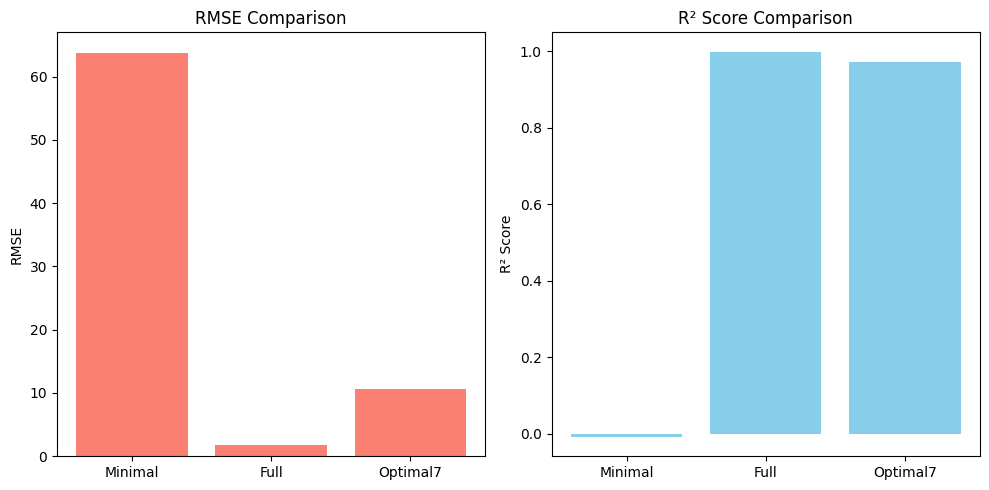

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. 데이터셋 정의 (칼로리 데이터프레임이 df_full에 저장되어 있다고 가정)
X_all = df_full.drop(columns=['User_ID', 'Calories', 'Height'], errors='ignore')
X_all = X_all.select_dtypes(include=['float64', 'int64'])  # 문자형 제거
y_all = df_full['Calories']

# 2. 전처리 방식별 변수 정의
minimal_features = ['Gender_encoded', 'BMI']
full_features = X_all.columns.tolist()
optimal_features = ['Duration', 'Heart_Rate', 'Gender_BMI_Interaction',
                    'Gender_encoded', 'Weight', 'BMI', 'Height_m']

# 3. 성능 저장용 리스트
results = []

# 4. 각 전처리 방식에 대해 학습 및 평가
for name, feature_set in [('Minimal', minimal_features),
                          ('Full', full_features),
                          ('Optimal7', optimal_features)]:

    # 데이터 분할
    X = X_all[feature_set]
    X_train, X_test, y_train, y_test = train_test_split(X, y_all, test_size=0.2, random_state=42)

    # 모델 학습
    model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
    model.fit(X_train, y_train)

    # 예측 및 평가
    y_pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        '전처리 방식': name,
        'RMSE': round(rmse, 2),
        'R² Score': round(r2, 4)
    })

# 5. 결과 정리
results_df = pd.DataFrame(results)
print(results_df)

# 6. 시각화
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.bar(results_df['전처리 방식'], results_df['RMSE'], color='salmon')
plt.title('RMSE Comparison')
plt.ylabel('RMSE')

plt.subplot(1, 2, 2)
plt.bar(results_df['전처리 방식'], results_df['R² Score'], color='skyblue')
plt.title('R² Score Comparison')
plt.ylabel('R² Score')

plt.tight_layout()
plt.show()

 Train/Test Performance Comparison by Pre-processing Method
     전처리 방식  Train_RMSE  Train_R²  Test_RMSE  Test_R²
0   Minimal       61.15    0.0328      63.80  -0.0087
1      Full        1.29    0.9996       1.84   0.9992
2  Optimal7        8.66    0.9806      10.70   0.9717


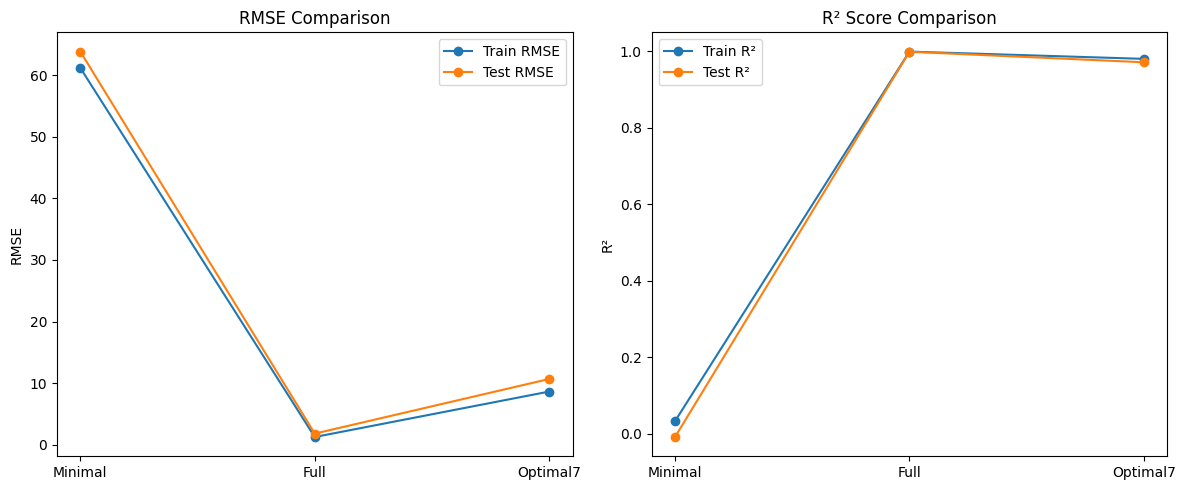

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. 입력 데이터 정의
X_all = df_full.drop(columns=['User_ID', 'Calories', 'Height'], errors='ignore')
X_all = X_all.select_dtypes(include=['float64', 'int64'])  # 문자형 제거
y_all = df_full['Calories']

# 2. 전처리 방식별 변수 구성
minimal_features = ['Gender_encoded', 'BMI']
full_features = X_all.columns.tolist()
optimal_features = ['Duration', 'Heart_Rate', 'Gender_BMI_Interaction',
                    'Gender_encoded', 'Weight', 'BMI', 'Height_m']

# 3. 결과 저장용 리스트
results = []

# 4. 각 전처리 방식별 학습 및 평가 (Train + Test)
for name, feature_set in [('Minimal', minimal_features),
                          ('Full', full_features),
                          ('Optimal7', optimal_features)]:

    # 데이터 선택 및 분할
    X = X_all[feature_set]
    X_train, X_test, y_train, y_test = train_test_split(X, y_all, test_size=0.2, random_state=42)

    # 모델 학습
    model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
    model.fit(X_train, y_train)

    # Train 성능
    y_train_pred = model.predict(X_train)
    rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
    r2_train = r2_score(y_train, y_train_pred)

    # Test 성능
    y_test_pred = model.predict(X_test)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))
    r2_test = r2_score(y_test, y_test_pred)

    # 결과 저장
    results.append({
        '전처리 방식': name,
        'Train_RMSE': round(rmse_train, 2),
        'Train_R²': round(r2_train, 4),
        'Test_RMSE': round(rmse_test, 2),
        'Test_R²': round(r2_test, 4)
    })

# 5. 결과 출력
results_df = pd.DataFrame(results)
print(" Train/Test Performance Comparison by Pre-processing Method")
print(results_df)

# 6. 시각화
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(results_df['전처리 방식'], results_df['Train_RMSE'], label='Train RMSE', marker='o')
plt.plot(results_df['전처리 방식'], results_df['Test_RMSE'], label='Test RMSE', marker='o')
plt.title('RMSE Comparison')
plt.ylabel('RMSE')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(results_df['전처리 방식'], results_df['Train_R²'], label='Train R²', marker='o')
plt.plot(results_df['전처리 방식'], results_df['Test_R²'], label='Test R²', marker='o')
plt.title('R² Score Comparison')
plt.ylabel('R²')
plt.legend()

plt.tight_layout()
plt.show()

##해석
# Minimal: Underfitting — 너무 단순
# Full:	완벽에 가까움 — 거의 차이 없음, 안정적
# Optimal7: 약한 과적합은 있지만 성능이 매우 높고 간결성도 있음 (해석력 + 단순성 을 고려하여 이후 모델용 전처리 방식으로 채택함)

# 모델 비교

모델별 성능 비교 (Optimal7 전처리)
             모델  Train_RMSE  Train_R²  Test_RMSE  Test_R²
0         Ridge       14.69    0.9441      15.03   0.9440
1  RandomForest        4.28    0.9953      11.22   0.9688
2       XGBoost        8.66    0.9806      10.70   0.9717
3           MLP       11.20    0.9676      11.37   0.9679


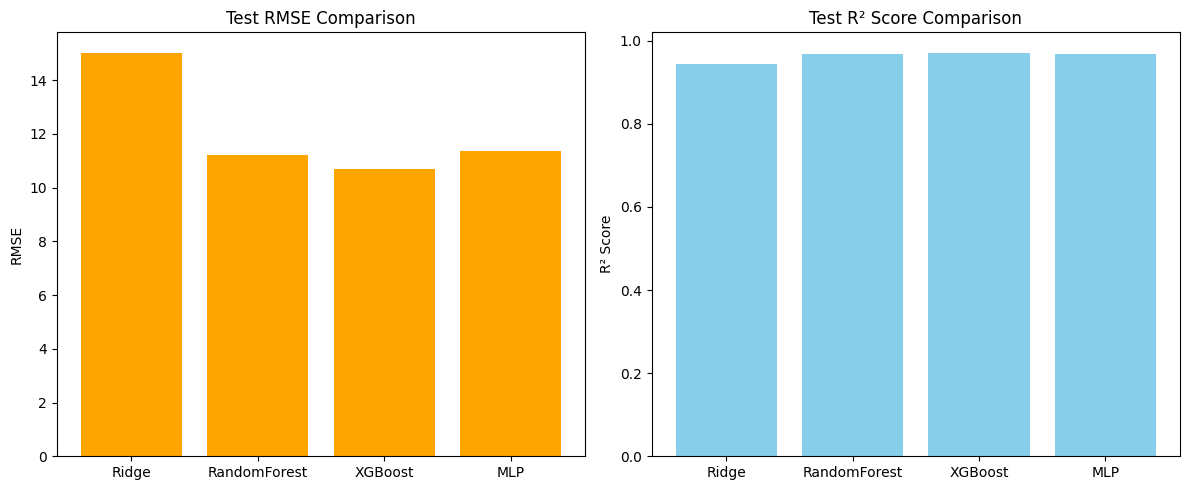

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. 데이터 구성
optimal_features = ['Duration', 'Heart_Rate', 'Gender_BMI_Interaction',
                    'Gender_encoded', 'Weight', 'BMI', 'Height_m']

X = df_full[optimal_features]
y = df_full['Calories']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. 모델 목록 정의
models = {
    'Ridge': Ridge(),
    'RandomForest': RandomForestRegressor(random_state=42),
    'XGBoost': XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    'MLP': MLPRegressor(hidden_layer_sizes=(50, 50), max_iter=500, random_state=42)
}

# 3. 결과 저장용 리스트
results = []

# 4. 각 모델 학습 및 성능 평가
for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
    r2_train = r2_score(y_train, y_pred_train)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
    r2_test = r2_score(y_test, y_pred_test)

    results.append({
        '모델': name,
        'Train_RMSE': round(rmse_train, 2),
        'Train_R²': round(r2_train, 4),
        'Test_RMSE': round(rmse_test, 2),
        'Test_R²': round(r2_test, 4)
    })

# 5. 결과 정리
results_df = pd.DataFrame(results)
print("모델별 성능 비교 (Optimal7 전처리)")
print(results_df)

# 6. 시각화
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.bar(results_df['모델'], results_df['Test_RMSE'], color='orange')
plt.title('Test RMSE Comparison')
plt.ylabel('RMSE')

plt.subplot(1, 2, 2)
plt.bar(results_df['모델'], results_df['Test_R²'], color='skyblue')
plt.title('Test R² Score Comparison')
plt.ylabel('R² Score')

plt.tight_layout()
plt.show()

## XGBoost 모델 채택

## 최적의 하이퍼파라미터 찾기 ㅡ GridSearchCV for XGBoost (Optimal7 전처리 기반)

In [ ]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

# 1. 데이터 구성
optimal_features = ['Duration', 'Heart_Rate', 'Gender_BMI_Interaction',
                    'Gender_encoded', 'Weight', 'BMI', 'Height_m']

X = df_full[optimal_features]
y = df_full['Calories']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. 탐색할 파라미터 그리드 정의
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# 3. 모델 정의 + GridSearchCV 실행
xgb = XGBRegressor(random_state=42, verbosity=0)
grid_search = GridSearchCV(estimator=xgb,
                           param_grid=param_grid,
                           scoring='neg_root_mean_squared_error',  # RMSE 기반
                           cv=3,
                           verbose=1,
                           n_jobs=-1)

grid_search.fit(X_train, y_train)

# 4. 최적 모델로 테스트셋 성능 평가
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# 5. 결과 출력
print(" Best Parameters:")
print(grid_search.best_params_)
print("\n Performance on Test Set:")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Fitting 3 folds for each of 48 candidates, totalling 144 fits
 Best Parameters:
{'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 50, 'subsample': 0.8}

 Performance on Test Set:
RMSE: 10.66
R² Score: 0.9718


## SHAP 해석: 튜닝된 XGBoost 기반

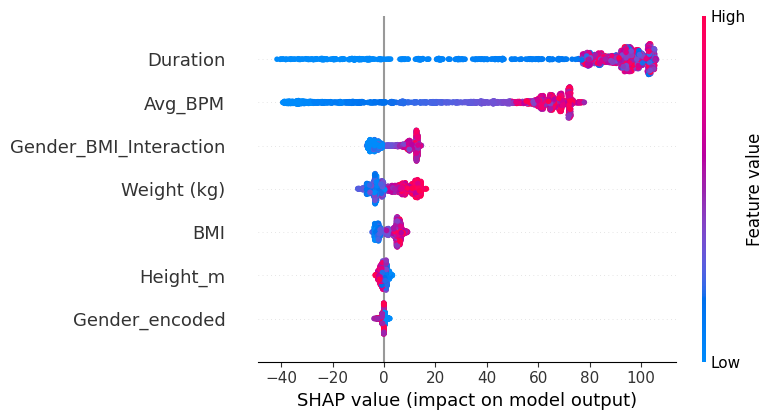

In [ ]:
import shap

# 1. TreeExplainer 생성
explainer = shap.Explainer(best_model)

# 2. SHAP 값 계산
shap_values = explainer(X_test)

# 3. 요약 플롯 (점 분포)
shap.summary_plot(shap_values, X_test)

# 운동 유형별 분할 분석

## 운동유형별 XGBoost 성능 비교

Saving gym_members_exercise_tracking.csv to gym_members_exercise_tracking.csv
 Workout Type별 칼로리 예측 성능
  Workout_Type   RMSE      R2  Train_Size  Test_Size
0       Cardio  56.04  0.9607         204         51
2     Strength  61.92  0.9432         206         52
3         Yoga  62.07  0.9462         191         48
1         HIIT  69.71  0.9500         176         45


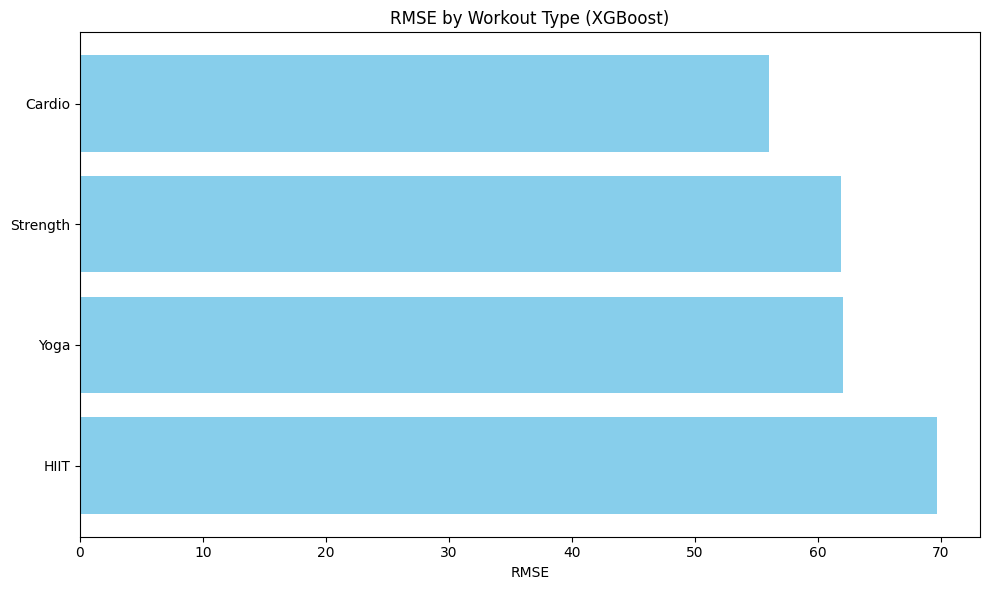

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor
import matplotlib.pyplot as plt

# 1. 데이터 불러오기
uploaded = files.upload()
file_path = "gym_members_exercise_tracking.csv"
df_gym = pd.read_csv("gym_members_exercise_tracking.csv")

# 2. 전처리 함수 정의
def preprocess_gym(df):
    df = df.copy()
    df.columns = [c.strip() for c in df.columns]
    le = LabelEncoder()
    df['Gender_encoded'] = le.fit_transform(df['Gender'])
    df['BMI'] = df['Weight (kg)'] / (df['Height (m)'] ** 2)
    df['Gender_BMI_Interaction'] = df['Gender_encoded'] * df['BMI']
    return df

# 3. 전처리 적용
df_gym = preprocess_gym(df_gym)

# 4. 변수 설정
features = ['Session_Duration (hours)', 'Avg_BPM', 'Gender_BMI_Interaction',
            'Gender_encoded', 'Weight (kg)', 'BMI', 'Height (m)']
target = 'Calories_Burned'
group_col = 'Workout_Type'

# 5. 결과 저장 리스트
results = []

# 6. 운동유형별 모델 학습
for workout_type, group in df_gym.groupby(group_col):
    if len(group) < 30:  # 너무 작은 그룹은 제외
        continue

    X = group[features]
    y = group[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model = XGBRegressor(n_estimators=50, learning_rate=0.1, max_depth=5, random_state=42)
    # n_estimators=50, max_depth=5는 이전 GridSearch에서 나온 좋은 조합
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Workout_Type': workout_type,
        'RMSE': round(rmse, 2),
        'R2': round(r2, 4),
        'Train_Size': len(X_train),
        'Test_Size': len(X_test)
    })

# 7. 결과 정리 및 시각화
results_df = pd.DataFrame(results).sort_values(by='RMSE')
print(" Workout Type별 칼로리 예측 성능")
print(results_df)

plt.figure(figsize=(10, 6))
plt.barh(results_df['Workout_Type'], results_df['RMSE'], color='skyblue')
plt.xlabel("RMSE")
plt.title("RMSE by Workout Type (XGBoost)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

 gym_members 데이터에 Optimal7 방식 적용 후 칼로리 예측 성능
RMSE: 62.37
R² Score: 0.9534


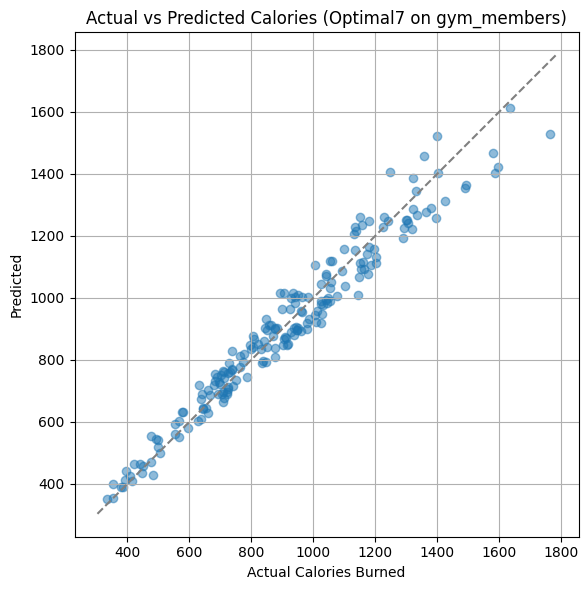

In [ ]:
# Optimal7 방식 전처리 적용
def preprocess_optimal7(df):
    df = df.copy()
    df.columns = [c.strip() for c in df.columns]
    le = LabelEncoder()
    df['Gender_encoded'] = le.fit_transform(df['Gender'])
    df['BMI'] = df['Weight (kg)'] / (df['Height (m)'] ** 2)
    df['Gender_BMI_Interaction'] = df['Gender_encoded'] * df['BMI']
    return df

df_gym = preprocess_optimal7(df_gym)

# 변수 설정
optimal7_features = ['Session_Duration (hours)', 'Avg_BPM', 'Gender_BMI_Interaction',
                     'Gender_encoded', 'Weight (kg)', 'BMI', 'Height (m)']
target = 'Calories_Burned'

X = df_gym[optimal7_features]
y = df_gym[target]

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 모델 학습
model = XGBRegressor(n_estimators=50, learning_rate=0.1, max_depth=5, random_state=42)
model.fit(X_train, y_train)

# 예측 및 평가
y_pred = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(" gym_members 데이터에 Optimal7 방식 적용 후 칼로리 예측 성능")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

# 예측 vs 실제 시각화
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], '--', color='gray')
plt.xlabel("Actual Calories Burned")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted Calories (Optimal7 on gym_members)")
plt.grid(True)
plt.tight_layout()
plt.show()